---
title: "L5-05 · Density operators and reduced states"
short_title: "Density operators and reduced states"
subtitle: "A density operator stores exactly what every measurement on a system can reveal; many different preparations, including half of an entangled pair, share one density operator, and the partial trace is the rule that extracts a subsystem's density operator from the whole."
description: "Represent mixtures and subsystems by density operators, calculate purity and Bloch vectors, and compute a partial trace with an explicit convention."
tags: [level-5, coursebook]
---

(lesson-l5-05)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 110 minutes  
**Big idea.** A density operator stores exactly what every measurement on a system can reveal; many different preparations, including half of an entangled pair, share one density operator, and the partial trace is the rule that extracts a subsystem's density operator from the whole.  
**Before this lesson.** [L5-04](#lesson-l5-04), [L3-05](#lesson-l3-05)  
**Lab.** [Noise and quantum channels](../../labs/07-noise-channels.ipynb)
:::

## What you will be able to do

- Form the density operator of an ensemble, check that a matrix is a valid density operator (Hermitian, positive semidefinite, trace one), and compute outcome probabilities as $\operatorname{Tr}(\Pi\rho)$.
- Convert a qubit density operator to its Bloch vector and compute its purity $\operatorname{Tr}\rho^2 = \tfrac12(1 + |\vec r|^2)$ and eigenvalues.
- Compute a reduced state with the stated partial-trace convention, and explain why different joint states and different ensembles can give the same reduced state.

## Why this matters

In [L5-04](#lesson-l5-04) a coin-flip source prepared $|00\rangle$ or $|11\rangle$ at random. No single state vector describes that source: a vector would have to be both $|00\rangle$ and $|11\rangle$. Worse, look at only qubit A of the Bell state $|\Phi^+\rangle$. Every measurement on A alone gives a fair coin in every basis, yet no state vector of one qubit does that: each pure state has a basis in which its outcome is certain.

Both puzzles have the same answer. The object that predicts measurement statistics is not the state vector but the density operator. It handles ignorance (coin flips), it handles subsystems of entangled states (through the partial trace), and it is the input and output of every noisy process in [L5-06](#lesson-l5-06). It also comes with a warning that runs through causal reasoning: one density operator can arise from many different preparations, so local data cannot tell them apart.

:::{dropdown} Key terms

**Density operator**
: $\rho = \sum_j p_j|\psi_j\rangle\langle\psi_j|$ for an ensemble; equivalently a Hermitian, positive semidefinite operator with trace 1.

**Mixed state**
: A density operator that is not of the form $|\psi\rangle\langle\psi|$; for a qubit, a point strictly inside the Bloch ball.

**Purity**
: $\operatorname{Tr}\rho^2$: 1 for pure states, down to $1/d$ for the maximally mixed state $I/d$.

**Bloch vector**
: The vector $\vec r = (\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$ with $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ and $|\vec r| \le 1$.

**Partial trace**
: The linear map $\operatorname{Tr}_B$ with $(\operatorname{Tr}_B\rho)_{ik} = \sum_j \rho_{ij,kj}$; it gives the reduced state of A.

**Reduced state**
: $\rho_A = \operatorname{Tr}_B\,\rho_{AB}$, the density operator that predicts every measurement on A alone.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_05 as _lessonfigs

## From state vectors to density operators

Suppose a source prepares the pure state $|\psi_j\rangle$ with probability $p_j$ (an **ensemble** $\{p_j, |\psi_j\rangle\}$). The probability of outcome $k$ in a measurement with orthonormal basis $\{|k\rangle\}$ is the average of the Born probabilities, $\sum_j p_j|\langle k|\psi_j\rangle|^2$. Writing $|\langle k|\psi\rangle|^2 = \langle k|\psi\rangle\langle\psi|k\rangle$ shows that only the combination $\sum_j p_j|\psi_j\rangle\langle\psi_j|$ ever enters [@nielsenchuang; @preskill].

:::{prf:definition} Density operator of an ensemble
:label: def-l5-05-rho
The density operator of the ensemble $\{p_j, |\psi_j\rangle\}$, with $p_j \ge 0$ and $\sum_j p_j = 1$, is $\rho = \sum_j p_j\,|\psi_j\rangle\langle\psi_j|$. It is **pure** if $\rho = |\psi\rangle\langle\psi|$ for one unit vector, and **mixed** otherwise.
:::

$$
P(k) = \langle k|\rho|k\rangle = \operatorname{Tr}(\Pi_k\,\rho), \qquad \langle A\rangle = \operatorname{Tr}(A\,\rho), \qquad \Pi_k = |k\rangle\langle k|
$$ (eq-l5-05-born)

:::{prf:proposition} Born rule for ensembles
:label: prop-l5-05-born
For the ensemble $\{p_j, |\psi_j\rangle\}$ with density operator $\rho$, the outcome probabilities and expectation values are given by [](#eq-l5-05-born).
:::

:::{prf:proof}
$P(k) = \sum_j p_j\,\langle k|\psi_j\rangle\langle\psi_j|k\rangle = \langle k|\big(\sum_j p_j|\psi_j\rangle\langle\psi_j|\big)|k\rangle = \langle k|\rho|k\rangle$, and $\langle k|\rho|k\rangle = \operatorname{Tr}(|k\rangle\langle k|\rho)$ by the cyclic property of the trace. For an observable $A = \sum_k a_k\Pi_k$ (its spectral decomposition, [L3-05](#lesson-l3-05)), $\langle A\rangle = \sum_k a_k P(k) = \operatorname{Tr}(A\rho)$ by linearity.
:::

:::{prf:theorem} Which matrices are density operators
:label: thm-l5-05-char
An operator $\rho$ is the density operator of some ensemble if and only if (i) $\rho = \rho^\dagger$, (ii) $\rho \ge 0$ (all eigenvalues nonnegative, equivalently $\langle v|\rho|v\rangle \ge 0$ for every $|v\rangle$), and (iii) $\operatorname{Tr}\rho = 1$.
:::

:::{prf:proof}
If $\rho = \sum_j p_j|\psi_j\rangle\langle\psi_j|$, each term is Hermitian, $\langle v|\rho|v\rangle = \sum_j p_j|\langle v|\psi_j\rangle|^2 \ge 0$, and $\operatorname{Tr}\rho = \sum_j p_j\langle\psi_j|\psi_j\rangle = 1$. Conversely, a Hermitian $\rho$ has a spectral decomposition $\rho = \sum_k \lambda_k|e_k\rangle\langle e_k|$ with orthonormal eigenvectors. Conditions (ii) and (iii) say $\lambda_k \ge 0$ and $\sum_k\lambda_k = 1$, so $\{\lambda_k, |e_k\rangle\}$ is an ensemble with density operator $\rho$.
:::

:::{prf:example} A diagonal mixed state
:label: ex-l5-05-diag
$\rho = \operatorname{diag}(0.8, 0.2)$ is a valid density operator. Its Z-basis probabilities are $0.8$ and $0.2$. Its square is $\operatorname{diag}(0.64, 0.04)$, so $\operatorname{Tr}\rho^2 = 0.68 < 1$: it is mixed. The zero off-diagonal entries say there is no coherence between $|0\rangle$ and $|1\rangle$; in the X basis the same operator has off-diagonal entries $0.3$, so coherence is always relative to a basis.
:::

## The Bloch ball and purity

For one qubit, the four matrices $I, X, Y, Z$ form a basis of the $2 \times 2$ matrices, and every Hermitian matrix is a real combination of them. Trace 1 fixes the coefficient of $I$. Convention: $|0\rangle$ sits at the north pole, $\vec r = (0, 0, 1)$, as in [L5-01](#lesson-l5-01).

:::{prf:theorem} The Bloch ball
:label: thm-l5-05-ball
Every qubit density operator can be written uniquely as $\rho = \tfrac12(I + xX + yY + zZ) = \tfrac12(I + \vec r\cdot\vec\sigma)$ with $\vec r = (\operatorname{Tr}\rho X, \operatorname{Tr}\rho Y, \operatorname{Tr}\rho Z)$ and $|\vec r| \le 1$. Its eigenvalues are $\lambda_\pm = \tfrac12(1 \pm |\vec r|)$, and $\rho$ is pure exactly when $|\vec r| = 1$.
:::

:::{prf:proof}
Hermitian $2 \times 2$ matrices are real combinations $aI + xX/2 + yY/2 + zZ/2$; trace 1 gives $a = 1/2$, and $\operatorname{Tr}(\rho X) = x$ because $\operatorname{Tr}X^2 = 2$ while $\operatorname{Tr}(XY) = \operatorname{Tr}(XZ) = \operatorname{Tr}X = 0$ (similarly for $y$, $z$). The matrix $\vec r\cdot\vec\sigma$ squares to $|\vec r|^2 I$ (the Pauli matrices anticommute in pairs and square to $I$) and has trace 0, so its eigenvalues are $\pm|\vec r|$, and those of $\rho$ are $\lambda_\pm = \tfrac12(1 \pm |\vec r|)$. Positivity is $\lambda_- \ge 0$, that is $|\vec r| \le 1$. A density operator is pure exactly when one eigenvalue is 1 and the other 0, that is $|\vec r| = 1$. As a consequence, the projector onto the pure state with Bloch vector $\vec n$ is $\Pi_{\vec n} = \tfrac12(I + \vec n\cdot\vec\sigma)$, and $\operatorname{Tr}(\sigma_i\sigma_j) = 2\delta_{ij}$ gives $\operatorname{Tr}(\Pi_{\vec n}\rho) = \tfrac12(1 + \vec n\cdot\vec r)$: the rule $P(+\vec n) = (1 + \vec n\cdot\vec r)/2$ promised in [L5-01](#lesson-l5-01), now for mixed states too.
:::

$$
\operatorname{Tr}\rho^2 = \tfrac12(1 + |\vec r|^2), \qquad \tfrac12 \le \operatorname{Tr}\rho^2 \le 1
$$ (eq-l5-05-purity)

:::{figure} ../../_static/animations/l5_05_purity_from_bloch.mp4
:alt: A derivation that transforms rho squared step by step into the purity formula, then a graph of purity against the length of the Bloch vector, rising from 1/2 at the center to 1 at the surface.
:width: 100%

Squaring $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ term by term gives $\operatorname{Tr}\rho^2 = \tfrac12(1 + |\vec r|^2)$: purity measures distance from the center of the ball.
:::

:::{dropdown} What the animation shows
The line $\rho^2 = \tfrac14(I + \vec r\cdot\vec\sigma)^2$ expands to $\tfrac14(I + 2\,\vec r\cdot\vec\sigma + (\vec r\cdot\vec\sigma)^2)$. A side note states $(\vec r\cdot\vec\sigma)^2 = |\vec r|^2 I$ because the Pauli matrices anticommute in pairs and each squares to $I$. The expression becomes $\tfrac14((1 + |\vec r|^2)I + 2\,\vec r\cdot\vec\sigma)$. Taking the trace, with $\operatorname{Tr} I = 2$ and every Pauli matrix traceless, gives $\operatorname{Tr}\rho^2 = \tfrac12(1 + |\vec r|^2)$. The eigenvalues $\lambda_\pm = \tfrac12(1 \pm |\vec r|)$ follow, both nonnegative exactly when $|\vec r| \le 1$. A graph of purity against $|\vec r|$ appears, and a dot runs along it from the center (the state $I/2$, purity $1/2$) through mixed states to the surface (pure states, purity 1).
:::

:::{prf:definition} Purity
:label: def-l5-05-purity
The purity of a density operator on a $d$-dimensional space is $\operatorname{Tr}\rho^2 = \sum_k \lambda_k^2$. Since $\sum_k \lambda_k = 1$ and $\lambda_k \ge 0$, it lies between $1/d$ (only for $\rho = I/d$, by the Cauchy-Schwarz inequality) and $1$ (only for pure states).
:::

Mixing is drawing straight lines. The Bloch vector is linear in $\rho$, so the mixture $\rho = p\,|0\rangle\langle 0| + (1-p)\,|+\rangle\langle +|$ has $\vec r = p\,\vec r_0 + (1-p)\,\vec r_+$, a point on the chord between the two pure states. At $p = 1/2$ the point is $(\tfrac12, 0, \tfrac12)$, with $|\vec r| = 1/\sqrt2 \approx 0.707$ and purity $\tfrac12(1 + \tfrac12) = 0.750$. The same point lies on other chords too, and every chord through it is another ensemble with the same density operator.

:::{figure} ../../_static/animations/l5_05_mixtures_in_ball.mp4
:alt: A three-dimensional Bloch ball. A point slides along the chord from |0> to |+> as the mixing weight changes, with live purity. Then a diameter and a second chord through the same point show two other ensembles, and the camera circles the ball.
:width: 100%

Mixtures of $|0\rangle$ and $|+\rangle$ fill the chord between them; at $p = 1/2$, two more ensembles (the eigenstates with weights 0.854 and 0.146, and a chord along y) pass through the same point.
:::

:::{dropdown} What the animation shows
A wireframe Bloch ball is labeled $|0\rangle$ at the top, $|1\rangle$ at the bottom, $|+\rangle$ and $|{+i}\rangle$ on the equator. The text $\rho = p\,|0\rangle\langle 0| + (1-p)\,|+\rangle\langle +|$ and $\vec r = p\,\vec r_0 + (1-p)\,\vec r_+$ is shown, with the formula $\operatorname{Tr}\rho^2 = \tfrac12(1 + |\vec r|^2)$. As $p$ goes from 1 to 0 and back to $0.5$, a point slides along the chord from $|0\rangle$ to $|+\rangle$; live readouts show $p$, $|\vec r|$ and the purity, which is 1 at the ends and $0.750$ at $p = 0.5$, where $|\vec r| = 0.707$. Then a diameter through the point appears: its ends are the eigenstates $\pm\hat r$ with weights $0.854$ and $0.146$. A second chord, from $(\tfrac12, \tfrac{1}{\sqrt2}, \tfrac12)$ to $(\tfrac12, -\tfrac{1}{\sqrt2}, \tfrac12)$ with weights $\tfrac12$ each, also passes through the point. The camera circles the ball, and the closing line says that the same point means the same density operator, so no measurement tells these ensembles apart.
:::


In [2]:
_show(_lessonfigs.bloch_mixer())

**Explore.** Move the weight $p$ of $|0\rangle$. The purple point is $\rho(p)$ on the blue chord; the dashed diameter is the eigen-ensemble with weights $\lambda_\pm = \tfrac12(1 \pm |\vec r|)$. Drag the ball to rotate it.

:::{dropdown} What the figure shows
A rotatable Bloch ball with the chord from $|0\rangle$ to $|+\rangle$. A slider sets $p$ from 0 to 1 in steps of 0.1. The purple marker shows the Bloch vector $(1 - p, 0, p)$ of $\rho(p) = p|0\rangle\langle 0| + (1-p)|+\rangle\langle +|$, and a dashed diameter through it joins the two eigenstates. The title reports $|\vec r|$, the purity and the eigen-weights; at $p = 0.5$ they are $0.707$, $0.750$, and $0.854$ and $0.146$.
:::

:::{prf:theorem} Ensembles with the same density operator
:label: thm-l5-05-freedom
Two ensembles $\{p_i, |\psi_i\rangle\}$ and $\{q_j, |\phi_j\rangle\}$ (padded with zero weights to equal length) have the same density operator if and only if $\sqrt{p_i}\,|\psi_i\rangle = \sum_j u_{ij}\sqrt{q_j}\,|\phi_j\rangle$ for some unitary matrix $(u_{ij})$ [@nielsenchuang].
:::

:::{prf:proof}
We prove the direction used here. Put $|\tilde\psi_i\rangle = \sqrt{p_i}|\psi_i\rangle$ and $|\tilde\phi_j\rangle = \sqrt{q_j}|\phi_j\rangle$. If $|\tilde\psi_i\rangle = \sum_j u_{ij}|\tilde\phi_j\rangle$, then $\sum_i |\tilde\psi_i\rangle\langle\tilde\psi_i| = \sum_{j,l}\big(\sum_i u_{ij}\overline{u_{il}}\big)|\tilde\phi_j\rangle\langle\tilde\phi_l| = \sum_j |\tilde\phi_j\rangle\langle\tilde\phi_j|$, because the columns of a unitary are orthonormal: $\sum_i \overline{u_{il}}u_{ij} = \delta_{lj}$. The converse expands both ensembles in the eigenbasis of $\rho$; see Nielsen and Chuang, Theorem 2.6.
:::

:::{warning} A decomposition is not a hidden fact
For a qubit at $\vec r \ne 0$, every chord through $\vec r$ is a valid ensemble; at the center, every diameter is. Since all measurement probabilities depend only on $\rho$ (Proposition [](#prop-l5-05-born)), no experiment on the system can reveal which ensemble was used. Do not read one decomposition as the preparation that really happened unless you have independent records of the source.
:::

## Reduced states and the partial trace

Now take a joint state $\rho_{AB}$ and ask for the statistics of measurements on A alone. We keep the convention of [L5-04](#lesson-l5-04): A is the left tensor factor, basis order $00, 01, 10, 11$, and matrix elements $\rho_{ij,kl} = \langle ij|\rho|kl\rangle$.

:::{prf:definition} Partial trace (convention)
:label: def-l5-05-ptrace
The partial trace over B is the linear map $\operatorname{Tr}_B$ defined by $(\operatorname{Tr}_B\rho)_{ik} = \sum_j \rho_{ij,kj}$, and the **reduced state** of A is $\rho_A = \operatorname{Tr}_B\,\rho_{AB}$. Symmetrically $(\operatorname{Tr}_A\rho)_{jl} = \sum_i \rho_{ij,il}$ gives $\rho_B$. On product operators, $\operatorname{Tr}_B(M \otimes N) = M\,\operatorname{Tr}N$.
:::

$$
\rho_{AB} = \begin{pmatrix} B_{00} & B_{01} \\ B_{10} & B_{11} \end{pmatrix} \;\Longrightarrow\; \operatorname{Tr}_B\,\rho_{AB} = \begin{pmatrix} \operatorname{Tr}B_{00} & \operatorname{Tr}B_{01} \\ \operatorname{Tr}B_{10} & \operatorname{Tr}B_{11} \end{pmatrix}, \qquad \operatorname{Tr}_A\,\rho_{AB} = B_{00} + B_{11}
$$ (eq-l5-05-blocks)

Because A is the left factor, the $4 \times 4$ matrix splits into $2 \times 2$ blocks $B_{ik}$ labeled by A's row and column, and each block holds B's indices. In index form, $(\operatorname{Tr}_B\rho)_{ik} = \sum_j \rho_{ij,kj}$ is the trace of block $B_{ik}$. In `numpy`, with `r = rho.reshape(2, 2, 2, 2)` (indices $i, j, k, l$), this is `einsum('ijkj->ik', r)`; the function `qcai.science.partial_trace(rho, keep=0)` uses the same convention.

:::{prf:theorem} What the reduced state predicts
:label: thm-l5-05-reduced
For every operator $M$ on A, $\operatorname{Tr}\big[(M \otimes I)\,\rho_{AB}\big] = \operatorname{Tr}\big[M\,\rho_A\big]$. Moreover $\rho_A = \operatorname{Tr}_B\rho_{AB}$ is the only operator with this property, and it is a density operator.
:::

:::{prf:proof}
In components, $\operatorname{Tr}[(M \otimes I)\rho] = \sum_{i,j,k} M_{ki}\,\rho_{ij,kj} = \sum_{i,k} M_{ki}(\operatorname{Tr}_B\rho)_{ik} = \operatorname{Tr}[M\rho_A]$, since $(M \otimes I)_{kj',ij} = M_{ki}\delta_{j'j}$. If another operator $\sigma$ satisfied $\operatorname{Tr}[M\sigma] = \operatorname{Tr}[M\rho_A]$ for all $M$, choosing $M = |k\rangle\langle i|$ gives $\sigma_{ik} = (\rho_A)_{ik}$ for all $i, k$. Finally, $M = I$ gives $\operatorname{Tr}\rho_A = 1$; $M = |v\rangle\langle v|$ gives $\langle v|\rho_A|v\rangle = \operatorname{Tr}[(|v\rangle\langle v| \otimes I)\rho_{AB}] \ge 0$; and $\rho_A^\dagger = \rho_A$ follows from the index formula.
:::

:::{figure} ../../_static/animations/l5_05_partial_trace_blocks.mp4
:alt: The 4 by 4 matrix of the Bell state with its four 2 by 2 blocks outlined; the partial trace adds the diagonal entries of each block to give I/2; then the matrix of the coin-flip mixture, which differs only in two corner entries, gives the same result.
:width: 100%

$\operatorname{Tr}_B$ in pictures: replace each $2 \times 2$ block by its trace. The Bell state and the coin-flip mixture differ only in a coherence that sits off the diagonal of the off-diagonal blocks, so both give $I/2$.
:::

:::{dropdown} What the animation shows
The matrix $|\Phi^+\rangle\langle\Phi^+|$ is shown with rows and columns labeled 00, 01, 10, 11: entries $1/2$ in the four corners and 0 elsewhere. Four colored squares outline the $2 \times 2$ blocks; the block rows and columns belong to qubit A. The formula $(\operatorname{Tr}_B\rho)_{ik} = \sum_j \rho_{ij,kj}$ is written, then $\operatorname{Tr}_B\rho$ as the matrix of block traces $\operatorname{Tr}B_{00}$, $\operatorname{Tr}B_{01}$, $\operatorname{Tr}B_{10}$, $\operatorname{Tr}B_{11}$. The diagonal entries of each block are highlighted and the matrix becomes $\tfrac12 + 0$, $0 + 0$, $0 + 0$, $0 + \tfrac12$, that is $I/2$. The corner coherences, at positions (00, 11) and (11, 00), are circled: they lie inside the off-diagonal blocks $B_{01}$ and $B_{10}$ but off their diagonals, so the partial trace drops them. The matrix then changes to the coin-flip mixture, where those corners are 0, and the reduced state is still $I/2$: same reduced state, different joint states.
:::


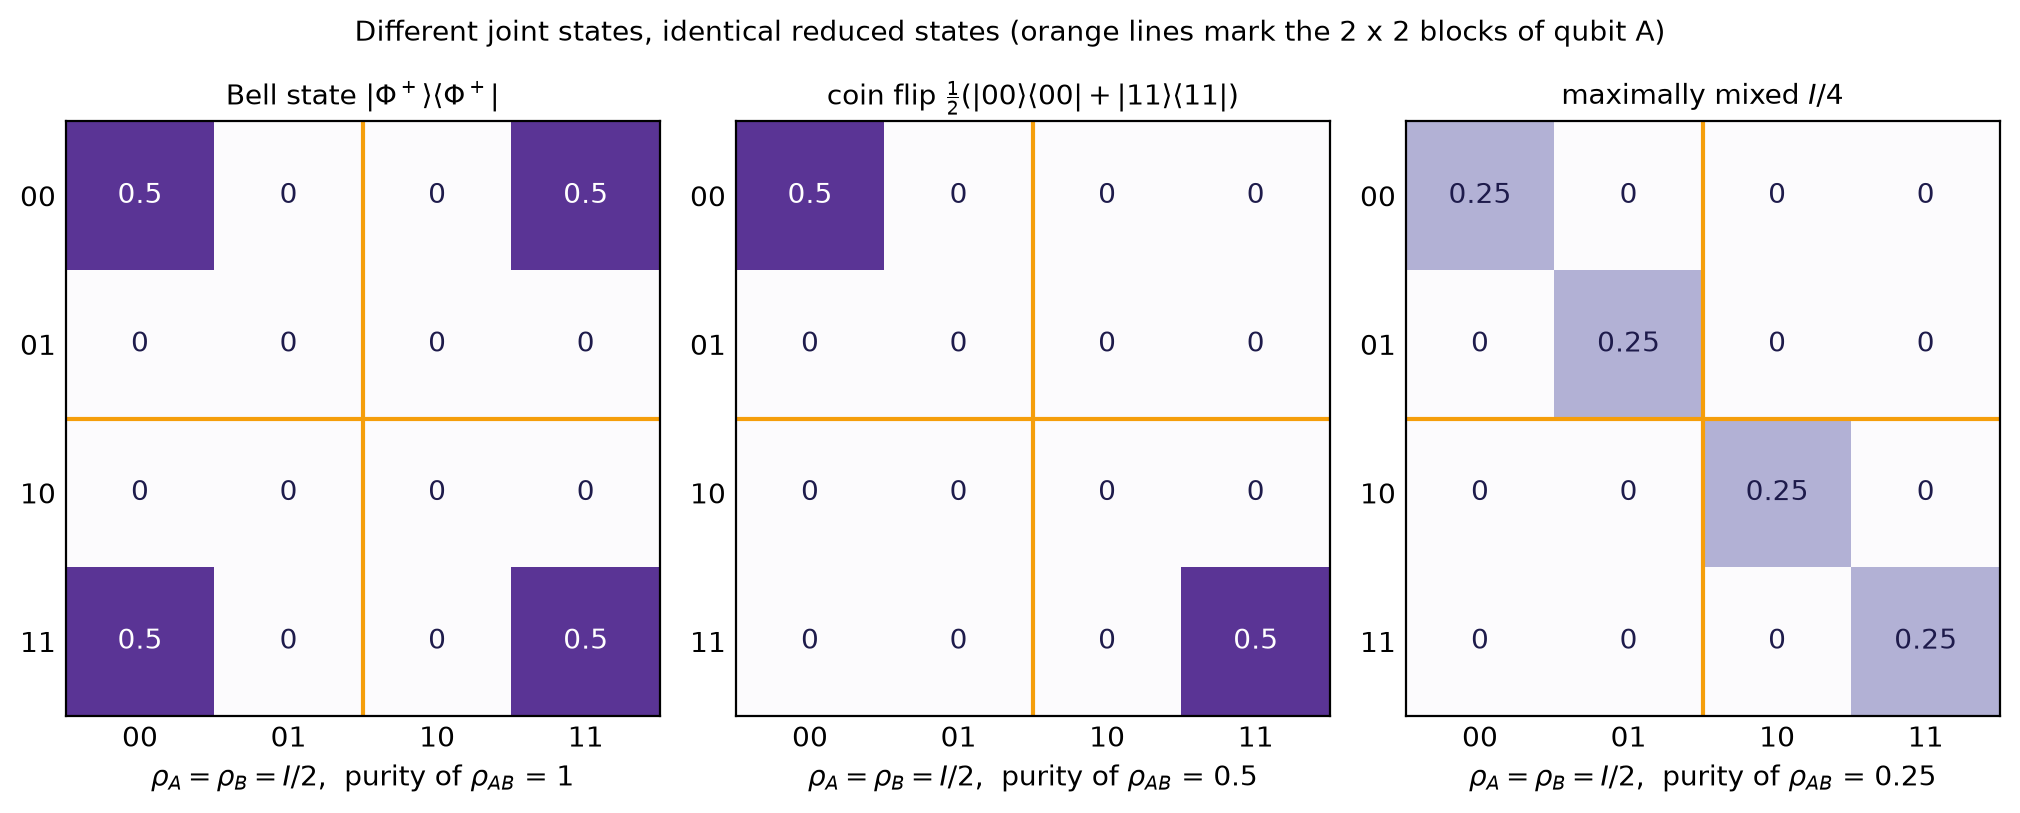

In [3]:
_show_mpl(_lessonfigs.joint_vs_reduced())

*Three joint states with purities 1, 0.5 and 0.25, and identical reduced states $\rho_A = \rho_B = I/2$. Local measurements on either qubit cannot distinguish them; only joint measurements, as in the X-basis test of [L5-04](#lesson-l5-04), can.*

:::{prf:proposition} Reduced states of a pure joint state
:label: prop-l5-05-pure
If $|\psi\rangle = \sum_{ij} C_{ij}|ij\rangle$, then $\rho_A = CC^\dagger$ and $\rho_B = (C^\dagger C)^T$. Both have eigenvalues $s_1^2, s_2^2$, the squared Schmidt coefficients. Hence $\rho_A$ and $\rho_B$ have the same purity $s_1^4 + s_2^4$, and $\rho_A$ is pure exactly when $|\psi\rangle$ is a product state.
:::

:::{prf:proof}
$(\operatorname{Tr}_B|\psi\rangle\langle\psi|)_{ik} = \sum_j C_{ij}\overline{C_{kj}} = (CC^\dagger)_{ik}$ and $(\operatorname{Tr}_A|\psi\rangle\langle\psi|)_{jl} = \sum_i C_{ij}\overline{C_{il}} = (C^T\bar C)_{jl} = ((C^\dagger C)^T)_{jl}$. With $C = U\Sigma V^\dagger$, $CC^\dagger = U\Sigma^2U^\dagger$ and $C^\dagger C = V\Sigma^2V^\dagger$; transposition keeps eigenvalues. So both spectra are $\{s_1^2, s_2^2\}$, and purity 1 means $s_1 = 1$, $s_2 = 0$: Schmidt rank 1, a product state by Theorem [](#thm-l5-04-schmidt).
:::

For $\cos\theta\,|00\rangle + \sin\theta\,|11\rangle$, $\rho_A = \operatorname{diag}(\cos^2\theta, \sin^2\theta)$ with Bloch vector $(0, 0, \cos 2\theta)$ and purity $\operatorname{Tr}\rho_A^2 = \tfrac12(1 + \cos^2 2\theta)$. As the entanglement grows the reduced state sinks from the pole to the center; at $\theta = \pi/4$ it is $I/2$, which answers the second puzzle of the motivation.

:::{figure} ../../_static/animations/l5_05_reduced_state_steering.mp4
:alt: In a Bloch ball, the reduced state of qubit A sinks from the north pole to the center as the entanglement angle grows. Then for the Bell state, two antipodal points showing Bob's conditional states rotate around the ball while their average stays at the center.
:width: 100%

Entanglement pulls the reduced state into the ball. For $|\Phi^+\rangle$, whatever Alice measures, Bob's two possible conditional states are antipodal with probability $\tfrac12$ each, so his reduced state stays $I/2$.
:::

:::{dropdown} What the animation shows
The state $|\psi\rangle = \cos\theta\,|00\rangle + \sin\theta\,|11\rangle$, its reduced state $\rho_A = \operatorname{diag}(\cos^2\theta, \sin^2\theta)$ and Bloch vector $\vec r_A = (0, 0, \cos 2\theta)$ are shown with the formula $\operatorname{Tr}\rho_A^2 = \tfrac12(1 + \cos^2 2\theta)$. As $\theta$ grows from 0 to $\pi/4$ (live readouts of $\theta$ and the purity), the point moves from the north pole to the center, where the purity is $1/2$: half of a Bell state is $I/2$. In the second part Alice measures her half along a direction $\vec n$ in the X-Z plane. With probability $\tfrac12$ each, Bob's half becomes $+\vec n$ or $-\vec n$, shown as two antipodal points joined by a dashed line, and $\tfrac12\,\vec n + \tfrac12\,(-\vec n) = \vec 0$. The direction rotates through three quarters of a turn while the camera circles; the average stays at the center, so Alice's choice sends no signal to Bob.
:::

:::{important} Tracing out is not throwing away
The partial trace is an information reduction: it is what someone who measures only A can predict. It does not mean that B was destroyed or that the correlations vanished; Theorem [](#thm-l5-05-reduced) says exactly which predictions survive. The animation also shows why there is no signaling: Alice's measurement splits Bob's $I/2$ into a different ensemble, but without her message Bob's density operator, and hence every statistic he can see, is unchanged [@preskill; @watrous].
:::

## Compute it

Density operators, validity, purity and Bloch vectors. The last part builds three different ensembles from the animation and checks that they give the same matrix.


In [4]:
import numpy as np

I2 = np.eye(2); X = np.array([[0, 1], [1, 0]]); Y = np.array([[0, -1j], [1j, 0]]); Z = np.diag([1.0, -1.0])

def dm(v):
    v = np.asarray(v, dtype=complex)
    return np.outer(v, v.conj())

def is_state(rho, tol=1e-9):
    herm = np.allclose(rho, rho.conj().T)
    evals = np.linalg.eigvalsh((rho + rho.conj().T) / 2)
    return bool(herm and evals.min() > -tol and abs(np.trace(rho) - 1) < tol)

def bloch(rho):
    return np.real([np.trace(rho @ P) for P in (X, Y, Z)])

rho = np.diag([0.8, 0.2])
print('diag(0.8, 0.2): valid', is_state(rho), ' purity', round(np.trace(rho @ rho).real, 4), ' Bloch', bloch(rho))
M = np.array([[0.5, 0.6], [0.6, 0.5]])
print('[[0.5,0.6],[0.6,0.5]]: valid', is_state(M), ' eigenvalues', np.round(np.linalg.eigvalsh(M), 3))

s = 1 / np.sqrt(2)
r = np.array([0.5, 0, 0.5])
n = r / np.linalg.norm(r)
lam = (1 + np.linalg.norm(r)) / 2
def pure(v):                      # pure state with Bloch vector v
    return (I2 + v[0] * X + v[1] * Y + v[2] * Z) / 2
ens1 = 0.5 * dm([1, 0]) + 0.5 * dm([s, s])
ens2 = lam * pure(n) + (1 - lam) * pure(-n)
ens3 = 0.5 * pure([0.5, s, 0.5]) + 0.5 * pure([0.5, -s, 0.5])
print('eigen-weights', round(lam, 3), round(1 - lam, 3))
print('three ensembles, one rho:', np.allclose(ens1, ens2), np.allclose(ens1, ens3), ' purity', round(np.trace(ens1 @ ens1).real, 3))

diag(0.8, 0.2): valid True  purity 0.68  Bloch [0.  0.  0.6]
[[0.5,0.6],[0.6,0.5]]: valid False  eigenvalues [-0.1  1.1]
eigen-weights 0.854 0.146
three ensembles, one rho: True True  purity 0.75


The partial trace with the stated convention. Testing on a product $\rho_A \otimes \rho_B$ with $\rho_A \ne \rho_B$ catches a swapped convention, which a Bell state would hide. Then the pure-state formula $\rho_A = CC^\dagger$, the sinking reduced state, and the steering average.


In [5]:
def ptrace_B(rho):                 # (Tr_B rho)_{ik} = sum_j rho_{ij,kj}; A is the left factor
    return np.einsum('ijkj->ik', rho.reshape(2, 2, 2, 2))

def ptrace_A(rho):                 # (Tr_A rho)_{jl} = sum_i rho_{ij,il}
    return np.einsum('ijil->jl', rho.reshape(2, 2, 2, 2))

rA, rB = dm([1, 0]), dm([s, s])     # |0><0| and |+><+|
prod = np.kron(rA, rB)
print('Tr_B(rA x rB) == rA:', np.allclose(ptrace_B(prod), rA), ' Tr_A(rA x rB) == rB:', np.allclose(ptrace_A(prod), rB))

bell = np.array([s, 0, 0, s])
rho_A = ptrace_B(dm(bell))
print('Bell: rho_A =', np.round(rho_A.real, 3).tolist(), ' purity', round(np.trace(rho_A @ rho_A).real, 3))

psi = np.array([1, 1, 1, 0]) / np.sqrt(3)   # worked example
C = psi.reshape(2, 2)
print('rho_A = C C^dagger:', np.allclose(ptrace_B(dm(psi)), C @ C.conj().T), ' rho_A =', np.round((C @ C.conj().T).real * 3, 3).tolist(), '/ 3')
print('Bloch', np.round(bloch(C @ C.conj().T), 4), ' purity', round(np.trace(ptrace_B(dm(psi)) @ ptrace_B(dm(psi))).real, 4))

for th in (0, np.pi / 8, np.pi / 4):
    rho_A = ptrace_B(dm([np.cos(th), 0, 0, np.sin(th)]))
    print(f'theta = {th:.3f}: purity {np.trace(rho_A @ rho_A).real:.4f}  formula {(1 + np.cos(2 * th) ** 2) / 2:.4f}')

# Alice measures along n = (sin a, 0, cos a): Bob's conditional states and their average
a = 1.1
for sign in (+1, -1):
    Pa = (I2 + sign * (np.sin(a) * X + np.cos(a) * Z)) / 2
    unnorm = ptrace_A(np.kron(Pa, I2) @ dm(bell) @ np.kron(Pa, I2))
    p = np.trace(unnorm).real
    print(f'outcome {sign:+d}: probability {p:.3f}, Bob Bloch vector {np.round(bloch(unnorm / p), 3)}')

Tr_B(rA x rB) == rA: True  Tr_A(rA x rB) == rB: True
Bell: rho_A = [[0.5, 0.0], [0.0, 0.5]]  purity 0.5
rho_A = C C^dagger: True  rho_A = [[2.0, 1.0], [1.0, 1.0]] / 3
Bloch [0.6667 0.     0.3333]  purity 0.7778
theta = 0.000: purity 1.0000  formula 1.0000
theta = 0.393: purity 0.7500  formula 0.7500
theta = 0.785: purity 0.5000  formula 0.5000
outcome +1: probability 0.500, Bob Bloch vector [0.891 0.    0.454]
outcome -1: probability 0.500, Bob Bloch vector [-0.891  0.    -0.454]


:::{prf:remark} Why the test state matters
:label: rem-l5-05-test
For $|\Phi^+\rangle$ both reduced states are $I/2$, so a code that silently computes $\operatorname{Tr}_A$ when you asked for $\operatorname{Tr}_B$ passes that test. Always check a convention on an asymmetric product state, as above, before trusting it.
:::

## Worked example

:::{admonition} Reduced state of a three-term state
:class: tip

Let $|\psi\rangle = \tfrac{1}{\sqrt3}(|00\rangle + |01\rangle + |10\rangle)$. Find $\rho_A$, its Bloch vector, purity and eigenvalues, and decide whether $|\psi\rangle$ is entangled.

1. Coefficient matrix (rows A, columns B): $C = \tfrac{1}{\sqrt3}\begin{pmatrix}1 & 1\\ 1 & 0\end{pmatrix}$.
2. Reduced state: $\rho_A = CC^\dagger = \tfrac13\begin{pmatrix}2 & 1\\ 1 & 1\end{pmatrix}$ (Proposition [](#prop-l5-05-pure)). Check with blocks: $\operatorname{Tr}B_{00} = \tfrac13 + \tfrac13$, $\operatorname{Tr}B_{01} = \rho_{00,10} + \rho_{01,11} = \tfrac13 + 0$, $\operatorname{Tr}B_{11} = \tfrac13 + 0$.
3. Bloch vector: $x = 2\operatorname{Re}\rho_{01} = \tfrac23$, $y = -2\operatorname{Im}\rho_{01} = 0$, $z = \rho_{00} - \rho_{11} = \tfrac13$, so $|\vec r|^2 = \tfrac59$.
4. Purity: $\operatorname{Tr}\rho_A^2 = \tfrac12(1 + \tfrac59) = \tfrac79 \approx 0.778$; directly, $\tfrac19(4 + 1 + 1 + 1) = \tfrac79$.
5. Eigenvalues: $\lambda_\pm = \tfrac12(1 \pm \tfrac{\sqrt5}{3}) \approx 0.873$ and $0.127$. Since $\rho_A$ is mixed, $|\psi\rangle$ is entangled; consistently $\det C = -\tfrac13 \ne 0$ and $s_1 s_2 = \tfrac13 = \sqrt{0.873 \times 0.127}$.

**Result.** $\rho_A = \tfrac13\begin{pmatrix}2 & 1\\ 1 & 1\end{pmatrix}$ with $\vec r = (\tfrac23, 0, \tfrac13)$ and purity $\tfrac79$; the state is entangled but not maximally, and by symmetry of $C$ the reduced state of B is the same matrix.
:::

## Exercises

**1. (Core)** Find the purity of $\operatorname{diag}(0.6, 0.4)$. Does it describe a pure qubit state?

:::{dropdown} Solution
Square the diagonal entries and add: $0.36 + 0.16 = 0.52 < 1$, so the state is mixed. Its Bloch vector is $(0, 0, 0.2)$ and indeed $\tfrac12(1 + 0.04) = 0.52$.
:::

**2. (Core)** Is $M = \begin{pmatrix}0.5 & 0.6\\ 0.6 & 0.5\end{pmatrix}$ a density operator? Use the Bloch picture.

:::{dropdown} Solution
$M$ is Hermitian with trace 1, and $M = \tfrac12(I + 1.2\,X)$, so its Bloch vector is $(1.2, 0, 0)$ with length $1.2 > 1$. Its eigenvalues are $\tfrac12(1 \pm 1.2) = 1.1$ and $-0.1$; the negative eigenvalue would give a negative probability for the outcome $|-\rangle$ ($\langle -|M|-\rangle = 0.5 - 0.6 = -0.1$). It is not a density operator.
:::

**3. (Stretch)** Show that the ensembles $\{\tfrac12, |0\rangle;\ \tfrac12, |1\rangle\}$ and $\{\tfrac12, |+\rangle;\ \tfrac12, |-\rangle\}$ have the same density operator, and find the unitary $u$ of Theorem [](#thm-l5-05-freedom) that relates them.

:::{dropdown} Solution
Both give $\tfrac12 I$: $\tfrac12(|0\rangle\langle 0| + |1\rangle\langle 1|) = \tfrac12 I$ and $\tfrac12(|+\rangle\langle +| + |-\rangle\langle -|) = \tfrac12 I$ by completeness of each basis. Put $|\tilde\psi_\pm\rangle = \tfrac{1}{\sqrt2}|\pm\rangle$ and $|\tilde\phi_j\rangle = \tfrac{1}{\sqrt2}|j\rangle$. Since $|\pm\rangle = \tfrac{1}{\sqrt2}(|0\rangle \pm |1\rangle)$, we get $|\tilde\psi_\pm\rangle = \tfrac{1}{\sqrt2}(|\tilde\phi_0\rangle \pm |\tilde\phi_1\rangle)$, so $u = H$, the Hadamard matrix, which is unitary. No measurement distinguishes the ensembles because all probabilities are $\operatorname{Tr}(\Pi\rho)$ with the same $\rho$.
:::

**4. (Stretch)** Prove from the index definition that $\operatorname{Tr}_B(\rho_A \otimes \rho_B) = \rho_A$ for density operators $\rho_A$, $\rho_B$, and that $\operatorname{Tr}_A(\rho_A \otimes \rho_B) = \rho_B$.

:::{dropdown} Solution
$(\rho_A \otimes \rho_B)_{ij,kl} = (\rho_A)_{ik}(\rho_B)_{jl}$. Then $(\operatorname{Tr}_B)_{ik} = \sum_j (\rho_A)_{ik}(\rho_B)_{jj} = (\rho_A)_{ik}\operatorname{Tr}\rho_B = (\rho_A)_{ik}$, and $(\operatorname{Tr}_A)_{jl} = \sum_i (\rho_A)_{ii}(\rho_B)_{jl} = (\rho_B)_{jl}$.
:::

**5. (Challenge)** The Werner state (Werner introduced this family with the singlet in place of $|\Phi^+\rangle$, which a local unitary relates to it [@werner1989]) is $\rho_v = v\,|\Phi^+\rangle\langle\Phi^+| + (1 - v)\,I/4$ with $0 \le v \le 1$. Find $\rho_A$, the eigenvalues of $\rho_v$, and its purity. For which $v$ is $\rho_v$ pure?

:::{dropdown} Solution
$\operatorname{Tr}_B$ is linear: $\operatorname{Tr}_B|\Phi^+\rangle\langle\Phi^+| = I/2$ and $\operatorname{Tr}_B(I/4) = I/2$, so $\rho_A = I/2$ for every $v$. $|\Phi^+\rangle$ is an eigenvector with eigenvalue $v + (1-v)/4 = (1 + 3v)/4$, and the three orthogonal Bell states have eigenvalue $(1 - v)/4$. Purity $= \big[(1 + 3v)^2 + 3(1 - v)^2\big]/16 = (4 + 12v^2)/16 = (1 + 3v^2)/4$, which equals 1 only at $v = 1$. The reduced state never changes, so no local measurement can estimate $v$.
:::

**6. (Challenge)** Show that for every pure joint state $|\psi\rangle_{AB}$ of two qubits, $\operatorname{Tr}\rho_A^2 = 1 - 2|\det C|^2$. Use it to find the purity of $\rho_A$ for $|\Phi^+\rangle$ and for $\tfrac{\sqrt3}{2}|00\rangle + \tfrac12|11\rangle$.

:::{dropdown} Solution
By Proposition [](#prop-l5-05-pure), $\operatorname{Tr}\rho_A^2 = s_1^4 + s_2^4 = (s_1^2 + s_2^2)^2 - 2s_1^2s_2^2 = 1 - 2(s_1s_2)^2 = 1 - 2|\det C|^2$, using $s_1s_2 = |\det C|$ from [L5-04](#lesson-l5-04). For $|\Phi^+\rangle$, $|\det C| = \tfrac12$ and the purity is $\tfrac12$. For the second state $|\det C| = \tfrac{\sqrt3}{4}$, so the purity is $1 - \tfrac{6}{16} = \tfrac58 = 0.625$, matching $(\tfrac34)^2 + (\tfrac14)^2$.
:::

## Check your understanding

**1. What is the purity of $\rho = \operatorname{diag}(0.8, 0.2)$?**

- **A.** 0.8
- **B.** 0.68
- **C.** 0.64
- **D.** 1

:::{dropdown} Show the answer
**B. 0.68**

$\operatorname{Tr}\rho^2 = 0.8^2 + 0.2^2 = 0.64 + 0.04 = 0.68$. Equivalently $|\vec r| = 0.6$ and $\tfrac12(1 + 0.36) = 0.68$.
:::

**2. What does a reduced density operator determine?**

- **A.** Every joint correlation
- **B.** Only the global preparation label
- **C.** All measurement probabilities on that subsystem

:::{dropdown} Show the answer
**C. All measurement probabilities on that subsystem**

By Theorem [](#thm-l5-05-reduced), $\rho_A$ fixes $\operatorname{Tr}[(M \otimes I)\rho_{AB}]$ for every $M$ on A, and nothing more: the Bell state and the coin-flip mixture have the same $\rho_A$ but different joint correlations.
:::

**3. A qubit has Bloch vector $(0.3, 0, 0.4)$. What is its purity?**

- **A.** 0.7
- **B.** 0.625
- **C.** 0.5
- **D.** 0.25

:::{dropdown} Show the answer
**B. 0.625**

$|\vec r|^2 = 0.09 + 0.16 = 0.25$, so $\operatorname{Tr}\rho^2 = \tfrac12(1 + 0.25) = 0.625$.
:::

**4. What is $\det C$ for the product state $|+\rangle|0\rangle$?** *(Review of [L5-04](#lesson-l5-04))*

- **A.** 1/2
- **B.** 0
- **C.** $1/\sqrt2$
- **D.** 1

:::{dropdown} Show the answer
**B. 0**

$C = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & 0\\ 1 & 0\end{pmatrix}$ has two equal rows, so $\det C = 0$; product states have Schmidt rank 1, and their reduced states are pure.
:::

## Common misconceptions

- **"A mixed state means the system is secretly in one of the pure states of its ensemble."** The same $\rho$ comes from infinitely many ensembles (every chord through the point in the Bloch ball) and also from entanglement with another system. Nothing in $\rho$ picks out one of them, so the ensemble is not a hidden fact about the system.
- **"The partial trace means system B was thrown away or destroyed."** It is the rule for predicting measurements on A alone. B still exists and the joint correlations are still there, as a joint measurement would show.
- **"A diagonal density matrix has no coherence."** Coherence is basis dependent. $\operatorname{diag}(0.8, 0.2)$ has no coherence between $|0\rangle$ and $|1\rangle$, but in the X basis its off-diagonal entries are $0.3$. Only $I/2$ is diagonal in every basis.
- **"Purity and trace are the same thing."** Every density operator has $\operatorname{Tr}\rho = 1$. Purity is $\operatorname{Tr}\rho^2$, which is 1 only for pure states and $1/2$ for $I/2$.

:::{caution} Scope and limits
Conventions: $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ with $|0\rangle$ at $\vec r = (0, 0, 1)$; A is the left tensor factor with basis order 00, 01, 10, 11; $(\operatorname{Tr}_B\rho)_{ik} = \sum_j \rho_{ij,kj}$. The density operator predicts measurement statistics for many identically prepared copies; it does not describe the outcome of one run, and it does not identify which ensemble or which joint state produced it. The steering picture uses an ideal projective measurement by Alice in the X-Z plane on $|\Phi^+\rangle$; general measurements are treated in [L5-07](#lesson-l5-07). All numbers here are exact calculations, not experimental estimates.
:::

:::{seealso} Where this leads
[L5-06](#lesson-l5-06) maps density operators to density operators and asks which maps stay valid when a reference system is attached; the partial trace of this lesson is how a channel arises from a unitary on system and environment. [L5-09](#lesson-l5-09) measures mixedness with the von Neumann entropy and reconstructs $\rho$ from data, and [L6-02](#lesson-l6-02) encodes channels as operators on two systems (Choi operators).
:::

:::{dropdown} For instructors

**Why this lesson.** Students who learn density matrices as a formula often think a mixture is a list of hidden pure states. The Bloch ball makes the non-uniqueness visible, and the partial trace of the Bell state shows mixedness without any ignorance about the joint system [@nielsenchuang; @preskill].

**Teaching notes.**

- Start from the two puzzles of the motivation and ask students to find a single vector that reproduces a fair coin in every basis; let them discover it cannot exist.
- Use the interactive ball: fix $p = 0.5$ and ask students to name three ensembles that land on the same point before showing the animation.
- Have students compute $\operatorname{Tr}_B$ on $|0\rangle\langle 0| \otimes |+\rangle\langle +|$ by hand to fix the convention; then swap the factor order and see what breaks.
- Connect the steering animation to no signaling: ask what Bob would need from Alice to update his description.

**Assessment.** The worked example and the second challenge exercise test the reduced-state computation and its link to Schmidt coefficients; the second core exercise tests validity checking; the check questions test purity and the meaning of a reduced state.

**Going further.** Show that every density operator is the reduced state of a pure state on a larger system (purification): for $\rho = \sum_k\lambda_k|e_k\rangle\langle e_k|$ take $|\Psi\rangle = \sum_k\sqrt{\lambda_k}|e_k\rangle|k\rangle$. Then connect Theorem [](#thm-l5-05-freedom) to the fact that all purifications are related by a unitary on the extra system. Watrous develops both results in general [@watrous].

:::

## References

This lesson draws on [@nielsenchuang; @preskill; @watrous; @werner1989].

**Further reading.**

- [@nielsenchuang]: Section 2.4 introduces density operators, the Bloch ball, Theorem 2.6 on ensembles, and the partial trace.
- [@watrous]: Develops density operators, partial traces and purifications in full generality.

**Next:** [L5-06 · Quantum channels and complete positivity](#lesson-l5-06)
